In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"
import seaborn as sns

In [2]:
df_district_demo = pd.read_excel(r"C:\Users\hp\Downloads\phonepe-pulse_raw-data_q12018-to-q22021-v0-1-5-1720351752.xlsx", sheet_name = "District Demographics")
df_district_txn = pd.read_excel(r"C:\Users\hp\Downloads\phonepe-pulse_raw-data_q12018-to-q22021-v0-1-5-1720351752.xlsx", sheet_name = "District_Txn and Users")
df_state_device = pd.read_excel(r"C:\Users\hp\Downloads\phonepe-pulse_raw-data_q12018-to-q22021-v0-1-5-1720351752.xlsx", sheet_name = "State_DeviceData")
df_state_txn = pd.read_excel(r"C:\Users\hp\Downloads\phonepe-pulse_raw-data_q12018-to-q22021-v0-1-5-1720351752.xlsx", sheet_name = "State_Txn and Users")
df_state_txn_split = pd.read_excel(r"C:\Users\hp\Downloads\phonepe-pulse_raw-data_q12018-to-q22021-v0-1-5-1720351752.xlsx", sheet_name = "State_TxnSplit")

In [83]:
## Task 1 - Data loadig & understanding
# 1.1 top 5 rows
df_district_demo.head()
df_district_txn.head()
df_state_device.head()
df_state_txn.head()
df_state_txn_split.head()

,State,District,Headquarters,Population,Area (sq km),Density,Code,Alternate Name
0,Andhra Pradesh,Anantapur,Anantapur,4083315,19130.0,213,AP01,Anantapur
1,Andhra Pradesh,Chittoor,Chittoor,4170468,15152.0,275,AP02,Chittoor
2,Andhra Pradesh,East Godavari,Kakinada,5151549,10807.0,477,AP03,East Godavari
3,Andhra Pradesh,Guntur,Guntur,4889230,11391.0,429,AP04,Guntur
4,Andhra Pradesh,YSR,Kadapa,2884524,15359.0,188,AP13,YSR


,State,Year,Quarter,District,Code,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,Nicobars,AN01,528,1.139849e+06,2158.804548,262,0
1,Andaman & Nicobar Islands,2018,1,North And Middle Andaman,AN02,442,9.316631e+05,2107.835016,632,0
2,Andaman & Nicobar Islands,2018,1,South Andaman,AN03,5688,1.256025e+07,2208.201361,5846,0
3,Andaman & Nicobar Islands,2018,2,Nicobars,AN01,1120,3.072437e+06,2743.247239,351,0
4,Andaman & Nicobar Islands,2018,2,North And Middle Andaman,AN02,825,1.317863e+06,1597.409798,911,0


,State,Year,Quarter,Brand,Registered Users,Percentage
0,Andaman & Nicobar Islands,2018,1,Xiaomi,1665,0.247033
1,Andaman & Nicobar Islands,2018,1,Samsung,1445,0.214392
2,Andaman & Nicobar Islands,2018,1,Vivo,982,0.145697
3,Andaman & Nicobar Islands,2018,1,Oppo,501,0.074332
4,Andaman & Nicobar Islands,2018,1,OnePlus,332,0.049258


,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,6658,1.463176e+07,2197.621091,6740,0
1,Andaman & Nicobar Islands,2018,2,11340,2.833854e+07,2498.989022,9405,0
2,Andaman & Nicobar Islands,2018,3,16265,5.555747e+07,3415.768284,12149,0
3,Andaman & Nicobar Islands,2018,4,23758,9.054834e+07,3811.277720,15222,0
4,Andaman & Nicobar Islands,2019,1,30486,1.022997e+08,3355.630147,18596,0


,State,Year,Quarter,Transaction Type,Transactions,Amount (INR),ATV (INR),YYYYQQ
0,Andaman & Nicobar Islands,2018,1,Recharge & bill payments,4200,1.845307e+06,439.358921,201801
1,Andaman & Nicobar Islands,2018,1,Peer-to-peer payments,1871,1.213866e+07,6487.790112,201801
2,Andaman & Nicobar Islands,2018,1,Merchant payments,298,4.525072e+05,1518.480432,201801
3,Andaman & Nicobar Islands,2018,1,Financial Services,33,1.060142e+04,321.255149,201801
4,Andaman & Nicobar Islands,2018,1,Others,256,1.846899e+05,721.444790,201801


In [10]:
#  1.1 - Bottom 10 rows
df_district_demo.tail(10)
df_district_txn.tail(10)
df_state_device.tail(10)
df_state_txn.tail(10)
df_state_txn_split.tail(10)

,State,District,Headquarters,Population,Area (sq km),Density,Code,Alternate Name
732,Delhi,North West Delhi,Kanjhawala,3656539,130.000,8254,DL06,North West
733,Delhi,Shahdara,Shahdara,0,59.750,0,DL07,Shahdara
734,Delhi,South Delhi,Saket,2731929,250.000,11060,DL08,South
735,Delhi,South East Delhi,Defence Colony,0,333.855,0,DL09,South East Delhi
736,Delhi,South West Delhi,Vasant Vihar,2292958,395.000,5446,DL10,South West
737,Delhi,West Delhi,Rajouri Garden,2543243,112.000,19563,DL11,West
738,Puducherry,Karaikal,Karaikal,200222,157.000,1275,PY01,Karaikal
739,Puducherry,Mahé,Mahé,41816,9.000,4646,PY02,Mahe
740,Puducherry,Puducherry,Pondicherry,950289,293.000,3232,PY03,Puducherry
741,Puducherry,Yanam,Yanam,55626,30.000,1854,PY04,Yanam


,State,Year,Quarter,District,Code,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
10238,West Bengal,2021,2,Murshidabad,WB14,8602251,1.999694e+10,2324.616616,1248602,16530655
10239,West Bengal,2021,2,Nadia,WB15,5524174,1.122758e+10,2032.445525,955428,13665885
10240,West Bengal,2021,2,North Twenty Four Parganas,WB16,17258291,3.041482e+10,1762.331031,2660664,37899453
10241,West Bengal,2021,2,Paschim Bardhaman,WB17,4893774,8.731263e+09,1784.157359,789026,10545670
10242,West Bengal,2021,2,Paschim Medinipur,WB18,5051834,1.030351e+10,2039.558976,856640,16201033
10243,West Bengal,2021,2,Purba Bardhaman,WB19,3920729,7.572502e+09,1931.401639,787970,12128849
10244,West Bengal,2021,2,Purba Medinipur,WB20,6418522,1.515507e+10,2361.146027,946277,15491958
10245,West Bengal,2021,2,Purulia,WB21,1895981,2.790996e+09,1472.059252,435131,8843358
10246,West Bengal,2021,2,South Twenty Four Parganas,WB22,6661813,1.339853e+10,2011.243709,1286588,19344293
10247,West Bengal,2021,2,Uttar Dinajpur,WB23,2253385,5.564221e+09,2469.272118,392388,8184990


,State,Year,Quarter,Brand,Registered Users,Percentage
5534,West Bengal,2021,2,Samsung,3778434,0.210147
5535,West Bengal,2021,2,Vivo,2703412,0.150357
5536,West Bengal,2021,2,Oppo,1970103,0.109572
5537,West Bengal,2021,2,Realme,1419072,0.078925
5538,West Bengal,2021,2,Motorola,402767,0.022401
5539,West Bengal,2021,2,Lenovo,350841,0.019513
5540,West Bengal,2021,2,Asus,297579,0.016551
5541,West Bengal,2021,2,Huawei,272965,0.015182
5542,West Bengal,2021,2,Apple,201393,0.011201
5543,West Bengal,2021,2,Others,1928653,0.107267


,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
494,West Bengal,2019,1,47626388,5.016467e+10,1053.295762,7449425,0
495,West Bengal,2019,2,47023535,5.710569e+10,1214.406597,8612795,49514201
496,West Bengal,2019,3,66444829,7.054053e+10,1061.640668,9643222,176559011
497,West Bengal,2019,4,96805838,8.820361e+10,911.139370,10885058,244326613
498,West Bengal,2020,1,66250381,9.665331e+10,1458.909424,11960822,207068218
499,West Bengal,2020,2,57676797,1.000994e+11,1735.523418,13222022,198589332
500,West Bengal,2020,3,79954504,1.568134e+11,1961.282329,14448366,246554831
501,West Bengal,2020,4,100340645,1.991655e+11,1984.893473,15662093,291721919
502,West Bengal,2021,1,118254052,2.429372e+11,2054.366877,16808799,316832674
503,West Bengal,2021,2,141897437,2.794348e+11,1969.273138,17979979,275341466


,State,Year,Quarter,Transaction Type,Transactions,Amount (INR),ATV (INR)
2504,West Bengal,2021,1,Peer-to-peer payments,53869075,2.022402e+11,3754.292226
2505,West Bengal,2021,1,Merchant payments,37143701,2.891834e+10,778.553104
2506,West Bengal,2021,1,Recharge & bill payments,26673733,1.133967e+10,425.124820
2507,West Bengal,2021,1,Financial Services,166727,1.754458e+08,1052.293941
2508,West Bengal,2021,1,Others,400816,2.635025e+08,657.415236
2509,West Bengal,2021,2,Peer-to-peer payments,64661051,2.308123e+11,3569.572026
2510,West Bengal,2021,2,Merchant payments,41696787,3.478787e+10,834.305703
2511,West Bengal,2021,2,Recharge & bill payments,34799709,1.333145e+10,383.090958
2512,West Bengal,2021,2,Financial Services,190537,1.864665e+08,978.636630
2513,West Bengal,2021,2,Others,549353,3.167447e+08,576.577748


In [11]:
## Explore the data
# 1.1 - Middle 10 rows - 

mid = len(df_state_device) // 2
df_state_device.iloc[mid - 5 : mid + 5]

,State,Year,Quarter,Brand,Registered Users,Percentage
2767,Ladakh,2021,2,OnePlus,1741,0.023198
2768,Ladakh,2021,2,Motorola,922,0.012285
2769,Ladakh,2021,2,Huawei,894,0.011912
2770,Ladakh,2021,2,Lenovo,490,0.006529
2771,Ladakh,2021,2,Others,2610,0.034778
2772,Lakshadweep,2018,1,Samsung,102,0.203593
2773,Lakshadweep,2018,1,Xiaomi,100,0.199601
2774,Lakshadweep,2018,1,Vivo,67,0.133733
2775,Lakshadweep,2018,1,Oppo,56,0.111776
2776,Lakshadweep,2018,1,Huawei,25,0.049900


In [15]:
# 1.1 every 10 th row
df_district_demo.iloc[::10]

,State,District,Headquarters,Population,Area (sq km),Density,Code,Alternate Name
0,Andhra Pradesh,Anantapur,Anantapur,4083315,19130.0,213,AP01,Anantapur
10,Andhra Pradesh,Visakhapatnam,Visakhapatnam,4288113,11161.0,384,AP10,Visakhapatnam
20,Arunachal Pradesh,Lepa Rada,Basar,0,0.0,0,AR08,Lepa Rada
30,Arunachal Pradesh,Siang,Pangin,31920,2919.0,11,AR18,Siang
40,Assam,Barpeta,Barpeta,1693622,3245.0,520,AS03,Barpeta
...,...,...,...,...,...,...,...,...
700,Chandigarh,Chandigarh,Chandigarh,1055450,114.0,9258,CH01,Chandigarh
710,Jammu & Kashmir,Jammu,Jammu,1526406,3097.0,596,JK07,Jammu
720,Jammu & Kashmir,Samba,Samba,318611,913.0,318,JK17,Samba
730,Delhi,North Delhi,Sadar Bazaar,887978,59.0,14557,DL04,North


In [7]:
# 1.2 - Display summary and statistics of all object columns in all 5 dataframes.

df_district_demo.describe(include = ["number"])
df_district_demo.describe(include = ["number"])
df_district_txn.describe(include = ["number"])
df_state_device.describe(include = ["number"])
df_state_txn.describe(include = ["number"])
df_state_txn_split.describe(include = ["number"])

,Population,Area (sq km),Density
count,7.420000e+02,742.000000,742.000000
mean,1.668555e+06,4395.373120,838.512129
std,1.458849e+06,4254.676124,2754.406896
min,0.000000e+00,0.000000,0.000000
25%,6.530815e+05,2039.750000,198.000000
50%,1.322359e+06,3402.500000,353.000000
75%,2.297440e+06,5432.750000,686.250000
max,1.008285e+07,45652.000000,36155.000000


,Population,Area (sq km),Density
count,7.420000e+02,742.000000,742.000000
mean,1.668555e+06,4395.373120,838.512129
std,1.458849e+06,4254.676124,2754.406896
min,0.000000e+00,0.000000,0.000000
25%,6.530815e+05,2039.750000,198.000000
50%,1.322359e+06,3402.500000,353.000000
75%,2.297440e+06,5432.750000,686.250000
max,1.008285e+07,45652.000000,36155.000000


,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
count,10248.000000,10248.000000,1.024800e+04,1.024800e+04,10244.000000,1.024800e+04,1.024800e+04
mean,2019.285714,2.357143,2.003607e+06,3.542311e+09,1909.796545,2.349591e+05,4.807117e+06
std,1.030208,1.108924,9.613466e+06,1.473154e+10,600.943349,4.605978e+05,1.562541e+07
min,2018.000000,1.000000,0.000000e+00,0.000000e+00,84.944283,2.200000e+01,0.000000e+00
25%,2018.000000,1.000000,1.031418e+05,1.756668e+08,1554.589051,3.619550e+04,0.000000e+00
50%,2019.000000,2.000000,3.763065e+05,6.784562e+08,1863.135530,1.067640e+05,6.403025e+05
75%,2020.000000,3.000000,1.272815e+06,2.377256e+09,2203.083552,2.573165e+05,4.346320e+06
max,2021.000000,4.000000,3.487128e+08,4.444224e+11,11209.980550,1.060461e+07,5.544197e+08


,Year,Quarter,Registered Users,Percentage
count,5544.000000,5544.000000,5.544000e+03,5544.000000
mean,2019.285714,2.357143,4.343183e+05,0.090909
std,1.030250,1.108970,9.056069e+05,0.083095
min,2018.000000,1.000000,1.000000e+01,0.006373
25%,2018.000000,1.000000,8.055750e+03,0.021588
50%,2019.000000,2.000000,7.442250e+04,0.056914
75%,2020.000000,3.000000,3.978875e+05,0.143626
max,2021.000000,4.000000,9.764252e+06,0.478367


,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
count,504.000000,504.000000,5.040000e+02,5.030000e+02,504.000000,5.040000e+02,5.040000e+02
mean,2019.285714,2.357143,4.074000e+07,7.083332e+10,1993.471543,4.777501e+06,9.774471e+07
std,1.031181,1.109971,8.228714e+07,1.440902e+11,607.464894,6.644496e+06,2.042376e+08
min,2018.000000,1.000000,7.780000e+02,1.928611e+06,0.000000,5.010000e+02,0.000000e+00
25%,2018.000000,1.000000,5.925578e+05,1.167157e+09,1598.910667,1.574202e+05,0.000000e+00
50%,2019.000000,2.000000,6.217487e+06,1.051605e+10,1861.380589,1.747914e+06,2.930574e+06
75%,2020.000000,3.000000,4.363675e+07,6.947045e+10,2259.087924,7.320945e+06,8.615022e+07
max,2021.000000,4.000000,5.736165e+08,1.027958e+12,3938.733850,3.966470e+07,1.208084e+09


,Year,Quarter,Transactions,Amount (INR),ATV (INR)
count,2514.000000,2514.000000,2.514000e+03,2.514000e+03,2514.000000
mean,2019.286794,2.358393,8.167446e+06,1.443978e+10,1349.927929
std,1.030807,1.109251,2.423645e+07,5.995054e+10,1534.866221
min,2018.000000,1.000000,2.000000e+00,3.439721e+01,17.198606
25%,2018.000000,1.000000,2.788075e+04,1.762412e+07,385.735827
50%,2019.000000,2.000000,2.687980e+05,1.901189e+08,720.940406
75%,2020.000000,3.000000,3.683230e+06,2.661248e+09,1352.790116
max,2021.000000,4.000000,2.795990e+08,8.721520e+11,7767.539936


In [9]:
## 1.2 - data type of each column in dataset

df_district_demo.dtypes
df_district_demo.dtypes
df_district_txn.dtypes
df_state_device.dtypes
df_state_txn.dtypes
df_state_txn_split.dtypes

State              object
District           object
Headquarters       object
Population          int64
Area (sq km)      float64
Density             int64
Code               object
Alternate Name     object
dtype: object

State              object
District           object
Headquarters       object
Population          int64
Area (sq km)      float64
Density             int64
Code               object
Alternate Name     object
dtype: object

State                object
Year                  int64
Quarter               int64
District             object
Code                 object
Transactions          int64
Amount (INR)        float64
ATV (INR)           float64
Registered Users      int64
App Opens             int64
dtype: object

State                object
Year                  int64
Quarter               int64
Brand                object
Registered Users      int64
Percentage          float64
dtype: object

State                object
Year                  int64
Quarter               int64
Transactions          int64
Amount (INR)        float64
ATV (INR)           float64
Registered Users      int64
App Opens             int64
dtype: object

State                object
Year                  int64
Quarter               int64
Transaction Type     object
Transactions          int64
Amount (INR)        float64
ATV (INR)           float64
dtype: object

In [3]:
# 1.3 - check for missing values
df_district_demo.isna().sum()
df_district_txn.isna().sum()
df_state_device.isna().sum()
df_state_txn.isna().sum()
df_state_txn_split.isna().sum()

State             0
District          0
Headquarters      0
Population        0
Area (sq km)      0
Density           0
Code              0
Alternate Name    0
dtype: int64

State                0
Year                 0
Quarter              0
District             0
Code                28
Transactions         0
Amount (INR)         0
ATV (INR)            4
Registered Users     0
App Opens            0
dtype: int64

State               0
Year                0
Quarter             0
Brand               0
Registered Users    0
Percentage          0
dtype: int64

State               0
Year                0
Quarter             0
Transactions        0
Amount (INR)        1
ATV (INR)           0
Registered Users    0
App Opens           0
dtype: int64

State               0
Year                0
Quarter             0
Transaction Type    0
Transactions        0
Amount (INR)        0
ATV (INR)           0
dtype: int64

In [ ]:
'''
df_district_demo
df_district_txn
df_state_device
df_state_txn
df_state_txn_split
'''

In [5]:
# 1.3 - calc. percentage of missing values in each dataset
df_district_demo.isna().mean()
df_district_txn.isna().mean()
df_state_device.isna().mean()
df_state_txn.isna().mean()
df_state_txn_split.isna().mean()

State             0.0
District          0.0
Headquarters      0.0
Population        0.0
Area (sq km)      0.0
Density           0.0
Code              0.0
Alternate Name    0.0
dtype: float64

State               0.000000
Year                0.000000
Quarter             0.000000
District            0.000000
Code                0.002732
Transactions        0.000000
Amount (INR)        0.000000
ATV (INR)           0.000390
Registered Users    0.000000
App Opens           0.000000
dtype: float64

State               0.0
Year                0.0
Quarter             0.0
Brand               0.0
Registered Users    0.0
Percentage          0.0
dtype: float64

State               0.000000
Year                0.000000
Quarter             0.000000
Transactions        0.000000
Amount (INR)        0.001984
ATV (INR)           0.000000
Registered Users    0.000000
App Opens           0.000000
dtype: float64

State               0.0
Year                0.0
Quarter             0.0
Transaction Type    0.0
Transactions        0.0
Amount (INR)        0.0
ATV (INR)           0.0
dtype: float64

State             0.0
District          0.0
Headquarters      0.0
Population        0.0
Area (sq km)      0.0
Density           0.0
Code              0.0
Alternate Name    0.0
dtype: float64


In [11]:
## 1.3 - column withhighest missing values
df_district_demo.isna().mean().idxmax()
df_district_txn.isna().mean().idxmax()
df_state_device.isna().mean().idxmax()
df_state_txn.isna().mean().idxmax()
df_state_txn_split.isna().mean().idxmax()

'State'

'Code'

'State'

'Amount (INR)'

'State'

In [31]:
## - 1.4 - calc total no. of states, districts
states_df_district_demo = df_district_demo['State'].nunique()
states_df_district_txn = df_district_txn['State'].nunique()
print(states_df_district_demo)
print(states_df_district_txn)

district_df_district_demo = df_district_demo['District'].nunique()
district_df_district_txn = df_district_txn['District'].nunique()
print(district_df_district_demo)
print(district_df_district_txn)

max_df_district_demo = df_district_demo['State'].value_counts().idxmax()
max_df_district_txn = df_district_txn['State'].value_counts().idxmax()
print(max_df_district_demo)
print(max_df_district_txn)

36
36
736
723
Uttar Pradesh
Uttar Pradesh


In [51]:
## Task 2 - exploratory data analysis
# 2.1 - Calculate the total number of transactions and total transaction amount for each state over the years

df_state_txn.groupby(['State', 'Year']).agg(total_transactions = ('Transactions', 'sum'), total_amount = ('Amount (INR)', 'sum')).reset_index()

# Identify the top 5 states with the highest transaction volumes and the top 5 states with the lowest transaction volumes
df_state_txn.groupby(['State'])['Transactions'].sum().idxmax()
df_state_txn.groupby(['State'])['Transactions'].sum().nlargest(5)
df_state_txn.groupby(['State'])['Transactions'].sum().nsmallest(5)

,State,Year,total_transactions,total_amount
0,Andaman & Nicobar Islands,2018,58021,1.890761e+08
1,Andaman & Nicobar Islands,2019,133104,4.734648e+08
2,Andaman & Nicobar Islands,2020,446274,1.296423e+09
3,Andaman & Nicobar Islands,2021,586166,1.682854e+09
4,Andhra Pradesh,2018,77779112,1.220720e+11
...,...,...,...,...
139,Uttarakhand,2021,44608834,7.727901e+10
140,West Bengal,2018,120011635,1.115887e+11
141,West Bengal,2019,257900590,2.660145e+11
142,West Bengal,2020,304222327,5.527316e+11


'Karnataka'

State
Karnataka         2981044533
Maharashtra       2833670154
Telangana         2347430243
Andhra Pradesh    1781091169
Rajasthan         1382918930
Name: Transactions, dtype: int64

State
Lakshadweep                    71610
Andaman & Nicobar Islands    1223565
Ladakh                       1880109
Mizoram                      2162776
Meghalaya                    5648913
Name: Transactions, dtype: int64

In [52]:
## 2.2 - # Identify the most common transaction types in each state Year and quarter
top_idx = df_state_txn_split.groupby(['State', 'Year', 'Quarter'])['Transactions'].idxmax()

df_state_txn_split.loc[top_idx]

,State,Year,Quarter,Transaction Type,Transactions,Amount (INR),ATV (INR)
0,Andaman & Nicobar Islands,2018,1,Recharge & bill payments,4200,1.845307e+06,439.358921
5,Andaman & Nicobar Islands,2018,2,Recharge & bill payments,6735,2.320945e+06,344.609463
10,Andaman & Nicobar Islands,2018,3,Recharge & bill payments,8636,4.343505e+06,502.953320
15,Andaman & Nicobar Islands,2018,4,Recharge & bill payments,11517,5.450550e+06,473.261224
20,Andaman & Nicobar Islands,2019,1,Recharge & bill payments,15263,6.611460e+06,433.169093
...,...,...,...,...,...,...,...
2489,West Bengal,2020,2,Peer-to-peer payments,24855687,8.498400e+10,3419.096979
2494,West Bengal,2020,3,Peer-to-peer payments,37556349,1.331207e+11,3544.558502
2499,West Bengal,2020,4,Peer-to-peer payments,46437233,1.663919e+11,3583.156529
2504,West Bengal,2021,1,Peer-to-peer payments,53869075,2.022402e+11,3754.292226


In [40]:
## 2.3 - Determine the device brand with the highest number of registered users in each state
users = df_state_device.groupby(['State', 'Brand'])['Registered Users'].sum().reset_index()
rows = users.groupby(['State'])['Registered Users'].idxmax()
users.loc[rows]

,State,Brand,Registered Users
11,Andaman & Nicobar Islands,Xiaomi,97889
22,Andhra Pradesh,Xiaomi,40061549
34,Arunachal Pradesh,Xiaomi,437803
46,Assam,Xiaomi,6979357
60,Bihar,Xiaomi,33721314
73,Chandigarh,Xiaomi,896628
85,Chhattisgarh,Xiaomi,8763373
98,Dadra & Nagar Haveli and Daman & Diu,Xiaomi,638834
109,Delhi,Xiaomi,24114984
120,Goa,Xiaomi,1208672


In [49]:
## 2.4 - for each state, identify the district with the highest population

idx = df_district_demo.groupby('State')['Population'].idxmax()
highest_population_districts = df_district_demo.loc[idx]
print(highest_population_districts[['State', 'District', 'Population']])

                                    State                District  Population
699             Andaman & Nicobar Islands           South Andaman      238142
2                          Andhra Pradesh           East Godavari     5151549
28                      Arunachal Pradesh              Papum Pare      176385
64                                  Assam                  Nagaon     2826006
97                                  Bihar                   Patna     5772804
700                            Chandigarh              Chandigarh     1055450
133                          Chhattisgarh                  Raipur     2160876
703  Dadra & Nagar Haveli and Daman & Diu  Dadra and Nagar Haveli      343709
732                                 Delhi        North West Delhi     3656539
138                                   Goa               North Goa      817761
140                               Gujarat               Ahmedabad     7208200
176                               Haryana               Faridaba

<Figure size 1000x600 with 0 Axes>

<BarContainer object of 36 artists>

Text(0, 238142, 'South Andaman')

Text(1, 5151549, 'East Godavari')

Text(2, 176385, 'Papum Pare')

Text(3, 2826006, 'Nagaon')

... (32 outputs left out)

Text(0.5, 0, 'State')

Text(0, 0.5, 'Population')

Text(0.5, 1.0, 'District with the Highest Population in Each State')

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35],
 [Text(0, 0, 'Andaman & Nicobar Islands'),
  Text(1, 0, 'Andhra Pradesh'),
  Text(2, 0, 'Arunachal Pradesh'),
  Text(3, 0, 'Assam'),
  Text(4, 0, 'Bihar'),
  Text(5, 0, 'Chandigarh'),
  Text(6, 0, 'Chhattisgarh'),
  Text(7, 0, 'Dadra & Nagar Haveli and Daman & Diu'),
  Text(8, 0, 'Delhi'),
  Text(9, 0, 'Goa'),
  Text(10, 0, 'Gujarat'),
  Text(11, 0, 'Haryana'),
  Text(12, 0, 'Himachal Pradesh'),
  Text(13, 0, 'Jammu & Kashmir'),
  Text(14, 0, 'Jharkhand'),
  Text(15, 0, 'Karnataka'),
  Text(16, 0, 'Kerala'),
  Text(17, 0, 'Ladakh'),
  Text(18, 0, 'Lakshadweep'),
  Text(19, 0, 'Madhya Pradesh'),
  Text(20, 0, 'Maharashtra'),
  Text(21, 0, 'Manipur'),
  Text(22, 0, 'Meghalaya'),
  Text(23, 0, 'Mizoram'),
  Text(24, 0, 'Nagaland'),
  Text(25, 0, 'Odisha'),
  Text(26, 0, 'Puducherry'),


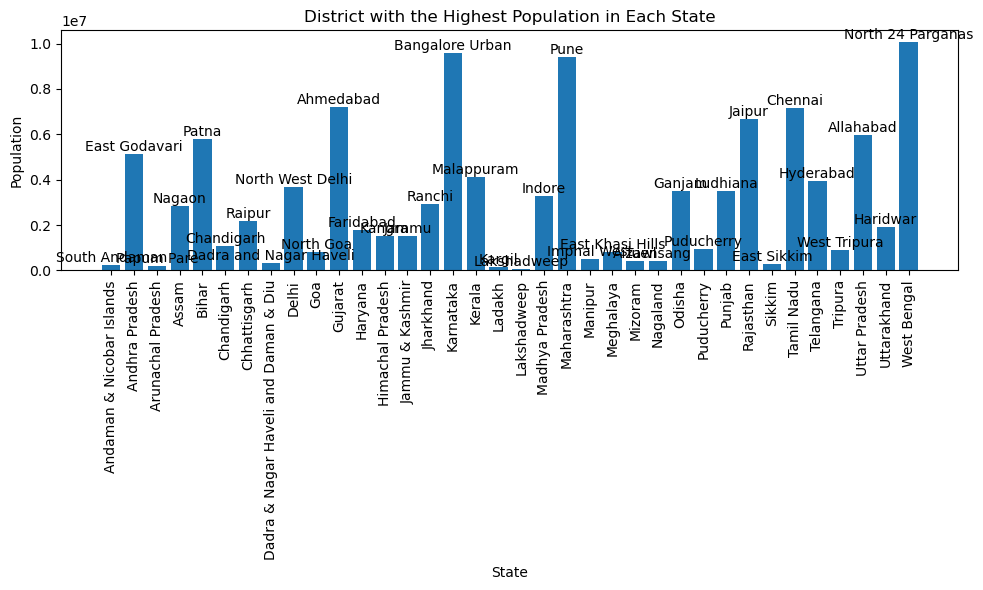

In [56]:
# column chart
plt.figure(figsize=(10, 6))
plt.bar(highest_population_districts['State'], highest_population_districts['Population'])

for i, row in enumerate(highest_population_districts.itertuples()):
    plt.text(i, row.Population, row.District,
             ha='center', va='bottom')

plt.xlabel('State')
plt.ylabel('Population')
plt.title('District with the Highest Population in Each State')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [57]:
## task 2.5 - atv avg. transaction value for each state
df_transactions = df_state_txn.groupby('State').agg(total_transactions = ('Transactions', 'sum'), 
                                                    total_amount = ('Amount (INR)', 'sum')).reset_index()
df_transactions['avg_transaction_per_user'] = df_transactions['total_amount']/df_transactions['total_transactions']


df_transactions.nlargest(5, columns = 'avg_transaction_per_user')
df_transactions.nsmallest(5, columns = 'avg_transaction_per_user')

,State,total_transactions,total_amount,avg_transaction_per_user
17,Ladakh,1880109,6.606978e+09,3514.146494
0,Andaman & Nicobar Islands,1223565,3.641818e+09,2976.399178
23,Mizoram,2162776,6.317141e+09,2920.848685
21,Manipur,12318043,3.579325e+10,2905.757931
24,Nagaland,5864977,1.638757e+10,2794.140997


,State,total_transactions,total_amount,avg_transaction_per_user
15,Karnataka,2981044533,4.361396e+12,1463.042846
7,Dadra & Nagar Haveli and Daman & Diu,12462185,1.865878e+10,1497.232192
20,Maharashtra,2833670154,4.290995e+12,1514.288897
35,West Bengal,942286041,1.452707e+12,1541.683482
8,Delhi,1011031124,1.649942e+12,1631.940078


,State,Year,Quarter,App Opens
0,Andaman & Nicobar Islands,2018,1,0
1,Andaman & Nicobar Islands,2018,2,0
2,Andaman & Nicobar Islands,2018,3,0
3,Andaman & Nicobar Islands,2018,4,0
4,Andaman & Nicobar Islands,2019,1,0
...,...,...,...,...
499,West Bengal,2020,2,198589332
500,West Bengal,2020,3,246554831
501,West Bengal,2020,4,291721919
502,West Bengal,2021,1,316832674


<Figure size 1600x900 with 0 Axes>

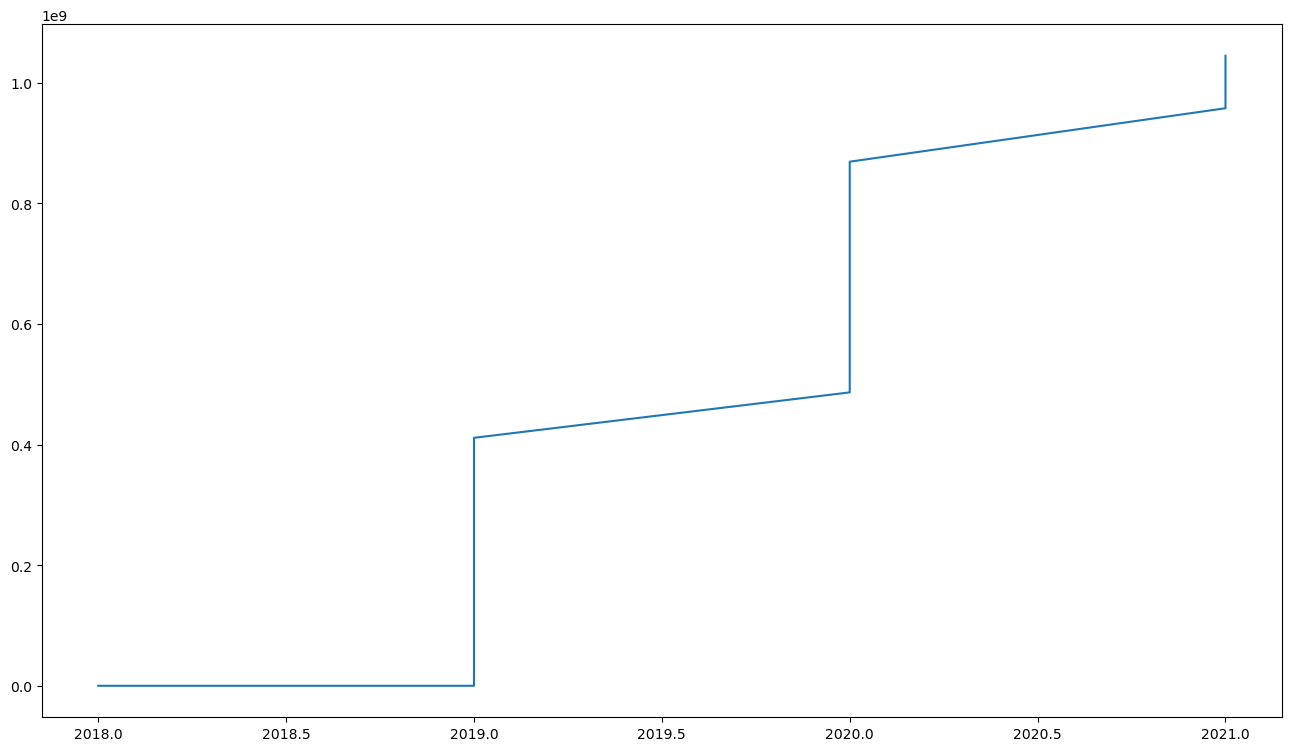

In [65]:
## Task 2.6 
# calc. app opens over the years for each state
app_opens = df_state_txn.groupby(['State', 'Year', 'Quarter'])['App Opens'].sum().reset_index()
app_opens

# identify trends in app usage by using line plot

state = 'Andhra Pradesh'
app_opens  = app_opens.sort_values(['Year', 'Quarter'])
app_opens['Year-Quarter'] = app_opens['Year'].astype(str)  + '-0' +  app_opens['Quarter'].astype(str)

plt.figure(figsize = (16, 9))
df_sub = app_opens[app_opens['State'] == state]
plt.plot(df_sub['Year'], df_sub['App Opens'])

,State,Year,Quarter,Transaction Type,Transactions,Amount (INR),ATV (INR),YYYYQQ
68,Andaman & Nicobar Islands,2021,2,Financial Services,960,2.038522e+06,2123.459910,202102
67,Andaman & Nicobar Islands,2021,2,Merchant payments,85143,1.037074e+08,1218.037989,202102
69,Andaman & Nicobar Islands,2021,2,Others,1628,1.327080e+06,815.159740,202102
65,Andaman & Nicobar Islands,2021,2,Peer-to-peer payments,132772,7.483820e+08,5636.595402,202102
66,Andaman & Nicobar Islands,2021,2,Recharge & bill payments,120911,4.369196e+07,361.356380,202102
...,...,...,...,...,...,...,...,...
2512,West Bengal,2021,2,Financial Services,190537,1.864665e+08,978.636630,202102
2510,West Bengal,2021,2,Merchant payments,41696787,3.478787e+10,834.305703,202102
2513,West Bengal,2021,2,Others,549353,3.167447e+08,576.577748,202102
2509,West Bengal,2021,2,Peer-to-peer payments,64661051,2.308123e+11,3569.572026,202102


<Figure size 1600x900 with 0 Axes>

<Axes: xlabel='State', ylabel='Transactions'>

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35],
 [Text(0, 0, 'Andaman & Nicobar Islands'),
  Text(1, 0, 'Andhra Pradesh'),
  Text(2, 0, 'Arunachal Pradesh'),
  Text(3, 0, 'Assam'),
  Text(4, 0, 'Bihar'),
  Text(5, 0, 'Chandigarh'),
  Text(6, 0, 'Chhattisgarh'),
  Text(7, 0, 'Dadra & Nagar Haveli and Daman & Diu'),
  Text(8, 0, 'Delhi'),
  Text(9, 0, 'Goa'),
  Text(10, 0, 'Gujarat'),
  Text(11, 0, 'Haryana'),
  Text(12, 0, 'Himachal Pradesh'),
  Text(13, 0, 'Jammu & Kashmir'),
  Text(14, 0, 'Jharkhand'),
  Text(15, 0, 'Karnataka'),
  Text(16, 0, 'Kerala'),
  Text(17, 0, 'Ladakh'),
  Text(18, 0, 'Lakshadweep'),
  Text(19, 0, 'Madhya Pradesh'),
  Text(20, 0, 'Maharashtra'),
  Text(21, 0, 'Manipur'),
  Text(22, 0, 'Meghalaya'),
  Text(23, 0, 'Mizoram'),
  Text(24, 0, 'Nagaland'),
  Text(25, 0, 'Odisha'),
  Text(26, 0, 'Puducherry'),


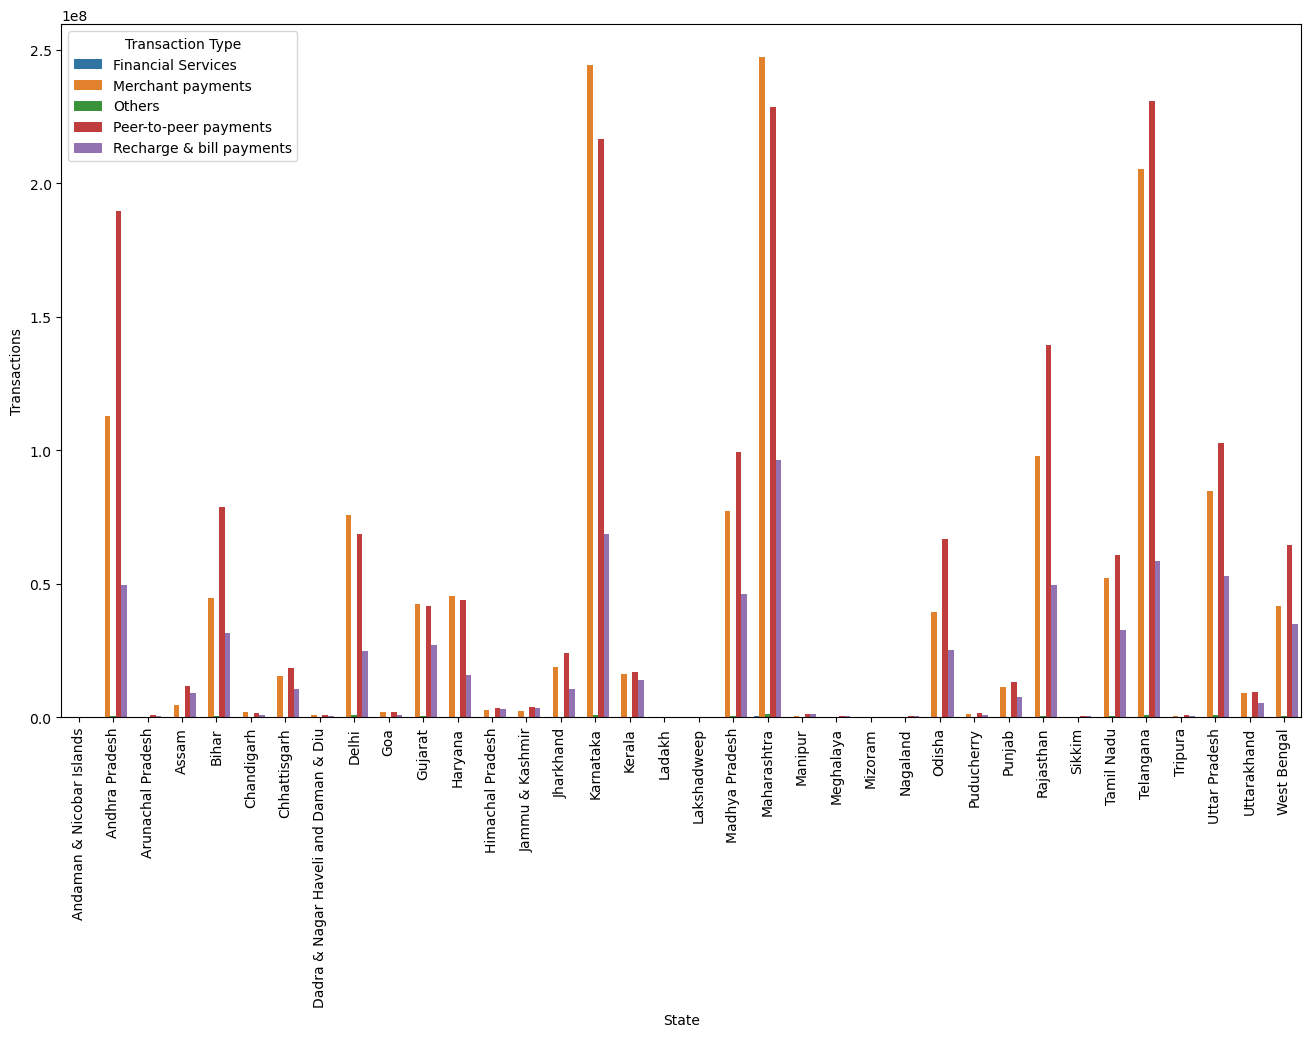

In [66]:
# 2.7 - bar chart - distribution of different transaction type for each state

df_state_txn_split['YYYYQQ'] = (df_state_txn_split['Year'].astype(str) + '0'+ df_state_txn_split['Quarter'].astype(str)).astype(int)

rows = df_state_txn_split.groupby(['State', 'Transaction Type'])['YYYYQQ'].idxmax()

df_sub = df_state_txn_split.loc[rows]
df_sub

plt.figure(figsize = (16, 9))
sns.barplot(x = df_sub['State'], y = df_sub['Transactions'], hue = df_sub['Transaction Type'])
plt.xticks(rotation = 90)

In [75]:
## 2.8 - 
# unique mapping b/w district names & district codes
unique_mapping = df_district_demo[
    ['District', 'Code']
].drop_duplicates()

unique_mapping

unique_mapping.to_csv("unique_Districts_&_Codes.csv", index = False)

,District,Code
0,Anantapur,AP01
1,Chittoor,AP02
2,East Godavari,AP03
3,Guntur,AP04
4,YSR,AP13
...,...,...
737,West Delhi,DL11
738,Karaikal,PY01
739,Mahé,PY02
740,Puducherry,PY03


In [73]:
## 2.8 
unique_mapping.to_csv("unique_Districts_&_Codes.csv", index = False)

In [94]:
## Task 3 - 
# 3.1 - Calculate the total number of transactions, total transaction amount, 
# and total registered users in each state by summing up the values from the district level data

df_district = df_district_txn.groupby(['State']).agg(district_transactions = ('Transactions', 'sum'), 
                                      district_transaction_amt = ('Amount (INR)', 'sum'),
                                      district_reg_users = ('Registered Users', 'sum')).reset_index()
df_district


# Calculate the total number of transactions, total transaction amount, 
# and total registered users in each state by summing up the values from the State level data

df_state = df_state_txn.groupby(['State']).agg(state_transactions = ('Transactions', 'sum'), 
                                      state_transaction_amt = ('Amount (INR)', 'sum'),
                                      state_reg_users = ('Registered Users', 'sum')).reset_index()
df_state


df_combined = df_state.merge(df_district, how = 'left', on = ['State'])

,State,district_transactions,district_transaction_amt,district_reg_users
0,Andaman & Nicobar Islands,1223565,3.641818e+09,408396
1,Andhra Pradesh,1781091169,3.860292e+12,158007957
2,Arunachal Pradesh,8043799,2.225183e+10,1862214
3,Assam,123577981,2.814087e+11,26860751
4,Bihar,713643889,1.639579e+12,115284760
5,Chandigarh,25516542,5.371208e+10,3801466
6,Chhattisgarh,241908549,4.156353e+11,37448388
7,Dadra & Nagar Haveli and Daman & Diu,12462185,1.865878e+10,2701112
8,Delhi,1011031124,1.649942e+12,95374654
9,Goa,24481604,4.427187e+10,4755320


,State,state_transactions,state_transaction_amt,state_reg_users
0,Andaman & Nicobar Islands,1223565,3.641818e+09,408396
1,Andhra Pradesh,1781091169,3.187847e+12,158007957
2,Arunachal Pradesh,8043799,2.225183e+10,1862214
3,Assam,123577981,2.814087e+11,26860751
4,Bihar,713643889,1.639579e+12,115284760
5,Chandigarh,25516542,5.371208e+10,3801466
6,Chhattisgarh,241908549,4.156353e+11,37448388
7,Dadra & Nagar Haveli and Daman & Diu,12462185,1.865878e+10,2701112
8,Delhi,1011031124,1.649942e+12,95374654
9,Goa,24481604,4.427187e+10,4755320


In [97]:
# 3.1 - compare
(df_combined['state_transactions'] == df_combined['state_transactions']).mean()
# similarly check for other columns


np.float64(1.0)

In [98]:
## task 4 - merge state txn and dist demo data
# 4.1
merged_st_demo = pd.merge(left = df_state_txn, right = df_district_demo, how = "inner", on = "State" )
merged_st_demo.head(3)


df = merged_st_demo.groupby("State")[["Registered Users", "Population"]].sum().reset_index()
df["Ratio b/w reg. popn and total popn"] = df["Registered Users"]/ df["Population"]
df.sort_values(by = "Ratio b/w reg. popn and total popn").head()


,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens,District,Headquarters,Population,Area (sq km),Density,Code,Alternate Name
0,Andaman & Nicobar Islands,2018,1,6658,1.463176e+07,2197.621091,6740,0,Nicobar,Car Nicobar,36842,1841.0,20,AN01,Nicobars
1,Andaman & Nicobar Islands,2018,1,6658,1.463176e+07,2197.621091,6740,0,North and Middle Andaman,Mayabunder,105597,3736.0,28,AN02,North and Middle Andaman
2,Andaman & Nicobar Islands,2018,1,6658,1.463176e+07,2197.621091,6740,0,South Andaman,Port Blair,238142,2672.0,89,AN03,South Andaman


,State,Registered Users,Population,Ratio b/w reg. popn and total popn
18,Lakshadweep,34223,902622,0.037915
0,Andaman & Nicobar Islands,1225188,5328134,0.229947
5,Chandigarh,3801466,14776300,0.257268
17,Ladakh,1159650,3876250,0.299168
22,Meghalaya,15801192,47108810,0.335419


<Figure size 1000x600 with 0 Axes>

<BarContainer object of 36 artists>

Text(0.5, 0, 'States')

Text(0, 0.5, 'Ratio of reg. popn and total popn')

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35],
 [Text(0, 0, 'Andaman & Nicobar Islands'),
  Text(1, 0, 'Andhra Pradesh'),
  Text(2, 0, 'Arunachal Pradesh'),
  Text(3, 0, 'Assam'),
  Text(4, 0, 'Bihar'),
  Text(5, 0, 'Chandigarh'),
  Text(6, 0, 'Chhattisgarh'),
  Text(7, 0, 'Dadra & Nagar Haveli and Daman & Diu'),
  Text(8, 0, 'Delhi'),
  Text(9, 0, 'Goa'),
  Text(10, 0, 'Gujarat'),
  Text(11, 0, 'Haryana'),
  Text(12, 0, 'Himachal Pradesh'),
  Text(13, 0, 'Jammu & Kashmir'),
  Text(14, 0, 'Jharkhand'),
  Text(15, 0, 'Karnataka'),
  Text(16, 0, 'Kerala'),
  Text(17, 0, 'Ladakh'),
  Text(18, 0, 'Lakshadweep'),
  Text(19, 0, 'Madhya Pradesh'),
  Text(20, 0, 'Maharashtra'),
  Text(21, 0, 'Manipur'),
  Text(22, 0, 'Meghalaya'),
  Text(23, 0, 'Mizoram'),
  Text(24, 0, 'Nagaland'),
  Text(25, 0, 'Odisha'),
  Text(26, 0, 'Puducherry'),


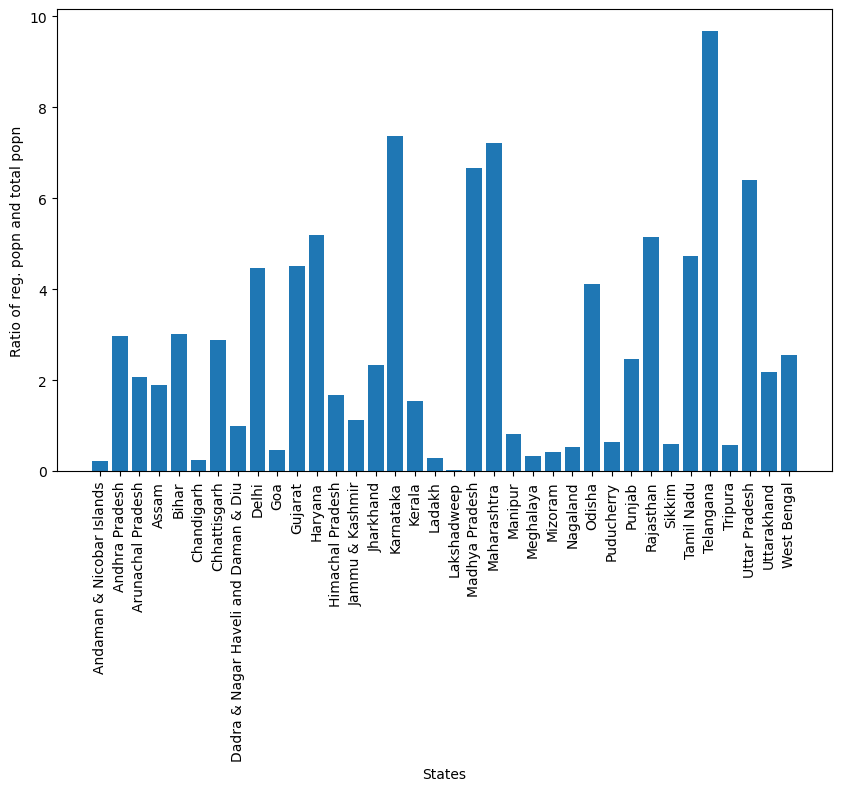

In [99]:
# 4.1 - column chart - ratio of users to population by state
plt.figure(figsize = (10,6))
plt.bar(df["State"], df["Ratio b/w reg. popn and total popn"])
plt.xlabel("States")
plt.ylabel("Ratio of reg. popn and total popn")
plt.xticks(rotation = 90)

In [100]:
# 4.2  - merge dist txn and dist demo
df1 = pd.merge(left = df_district_txn, right = df_district_demo, how = "inner", on = ["State","District"])
df1.head()

,State,Year,Quarter,District,Code_x,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens,Headquarters,Population,Area (sq km),Density,Code_y,Alternate Name
0,Andaman & Nicobar Islands,2018,1,South Andaman,AN03,5688,1.256025e+07,2208.201361,5846,0,Port Blair,238142,2672.0,89,AN03,South Andaman
1,Andaman & Nicobar Islands,2018,2,South Andaman,AN03,9395,2.394824e+07,2549.040502,8143,0,Port Blair,238142,2672.0,89,AN03,South Andaman
2,Andaman & Nicobar Islands,2018,3,South Andaman,AN03,13511,4.426811e+07,3276.449742,10474,0,Port Blair,238142,2672.0,89,AN03,South Andaman
3,Andaman & Nicobar Islands,2018,4,South Andaman,AN03,20136,7.541184e+07,3745.125189,13133,0,Port Blair,238142,2672.0,89,AN03,South Andaman
4,Andaman & Nicobar Islands,2019,1,South Andaman,AN03,25683,8.550197e+07,3329.127142,15961,0,Port Blair,238142,2672.0,89,AN03,South Andaman


In [102]:
# 4.2.2 - corelation b/w population density and transaction volume
df1 = df1.groupby("State")[["Transactions", "Population"]].sum().reset_index()
#df1.head(3)
corr = df1.groupby("State").apply(lambda x: x["Transactions"].corr(x["Population"])).reset_index(name = "Correlation")
corr = corr.sort_values(by = "Correlation", ascending = False)
corr.head()

C:\Users\hp\anaconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:2991: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
C:\Users\hp\anaconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:2848: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
C:\Users\hp\anaconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:2848: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)
C:\Users\hp\AppData\Local\Temp\ipykernel_7720\942934553.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  corr = df1.groupby("State").apply(lambda x: x["Transactions"].corr(x["Population"])).reset_index(name = 

,State,Correlation
0,Andaman & Nicobar Islands,NaN
1,Andhra Pradesh,NaN
2,Arunachal Pradesh,NaN
3,Assam,NaN
4,Bihar,NaN


<Figure size 1000x600 with 0 Axes>

Text(0.5, 0, 'State-wise population')

Text(0, 0.5, 'State-wise Transactions')

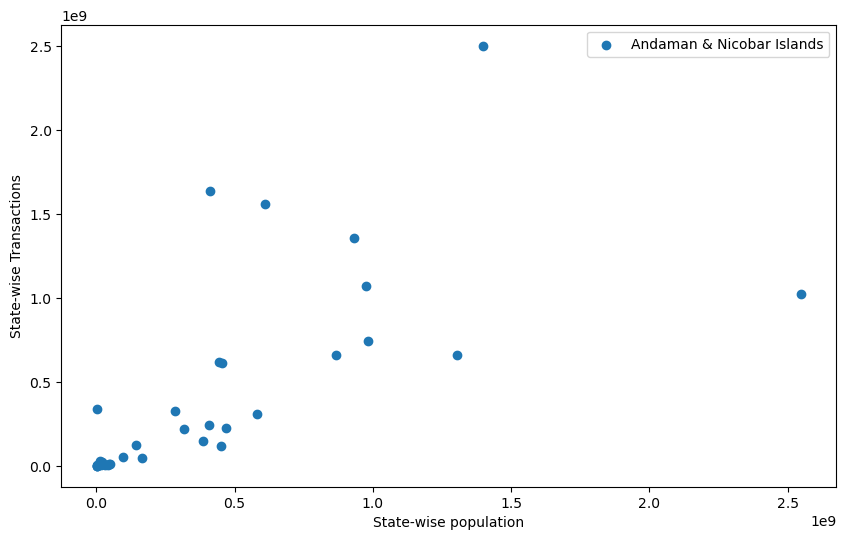

In [103]:
# 4.2.3 - scatter plot of corelation b/w population density and transaction volume

plt.figure(figsize = (10,6))
plt.scatter(df1["Population"], df1["Transactions"])
plt.xlabel("State-wise population")
plt.ylabel("State-wise Transactions")
plt.legend(df1["State"])

In [6]:
# Task 4.3 - avg. transaction amount per user
df_district_txn.groupby("State")[["Transactions", "ATV (INR)"]].sum()

# 4.3 - 
df_district_txn.groupby("State")[["Transactions", "ATV (INR)"]].sum().head(5)
df_district_txn.groupby("State")[["Transactions", "ATV (INR)"]].sum().tail(5)


,Transactions,ATV (INR)
State,,
Andaman & Nicobar Islands,1223565,1.374825e+05
Andhra Pradesh,1781091169,3.555595e+05
Arunachal Pradesh,8043799,9.267974e+05
Assam,123577981,8.498806e+05
Bihar,713643889,1.096524e+06
Chandigarh,25516542,2.959316e+04
Chhattisgarh,241908549,6.665593e+05
Dadra & Nagar Haveli and Daman & Diu,12462185,6.833818e+04
Delhi,1011031124,2.416972e+05


,Transactions,ATV (INR)
State,,
Andaman & Nicobar Islands,1223565,1.374825e+05
Andhra Pradesh,1781091169,3.555595e+05
Arunachal Pradesh,8043799,9.267974e+05
Assam,123577981,8.498806e+05
Bihar,713643889,1.096524e+06


,Transactions,ATV (INR)
State,,
Telangana,2347430243,9.519856e+05
Tripura,12018152,1.734282e+05
Uttar Pradesh,1314714390,1.862190e+06
Uttarakhand,124011162,3.079915e+05
West Bengal,942286041,4.436000e+05


Brand                                    Apple      Asus  COOLPAD    Gionee  \
State                                                                         
Andaman & Nicobar Islands             2.285527       NaN      NaN       NaN   
Andhra Pradesh                        2.579244       NaN      NaN       NaN   
Arunachal Pradesh                     2.019478       NaN      NaN  1.335776   
Assam                                 0.416586  1.493100      NaN  1.521584   
Bihar                                 0.316113       NaN      NaN       NaN   
Chandigarh                            8.088485       NaN      NaN       NaN   
Chhattisgarh                          1.569680       NaN      NaN       NaN   
Dadra & Nagar Haveli and Daman & Diu  1.945384       NaN      NaN       NaN   
Delhi                                 5.612451       NaN      NaN       NaN   
Goa                                   4.943243       NaN      NaN       NaN   
Gujarat                               3.664213      

<Figure size 1200x800 with 0 Axes>

<Axes: xlabel='State'>

Text(0, 0.5, 'Percentage of Registered Users')

Text(0.5, 1.0, 'Stacked Column Chart of Registered Users by Brand and State')

<Figure size 1200x800 with 0 Axes>

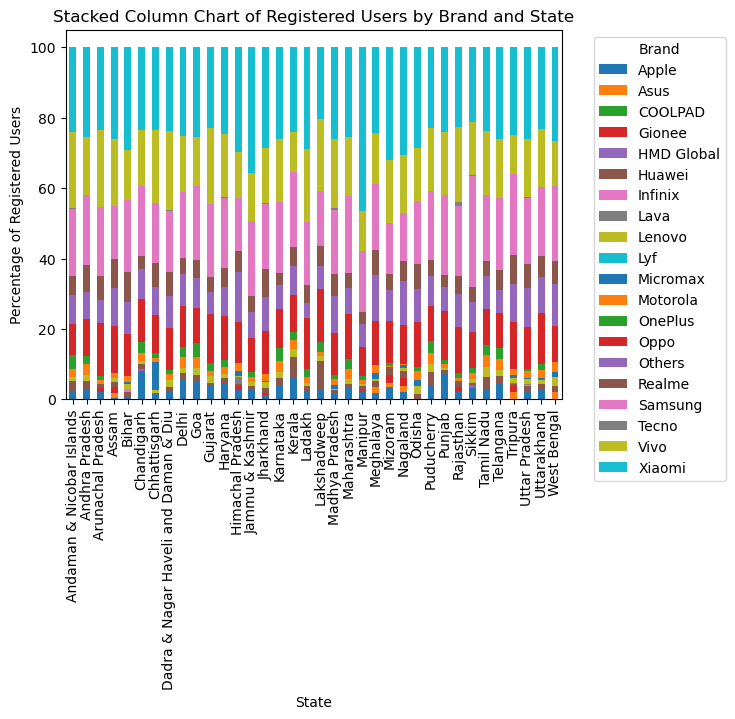

In [16]:
# Task 4.4 - device brand usage ratio
# 4.4.1
df_brand_totaluser_ratio = (df_state_device.groupby(["State", "Brand"])["Registered Users"].sum() /df_state_device.groupby("State")["Registered Users"].sum()) * 100
df_brand_totaluser_ratio = df_brand_totaluser_ratio.reset_index()

pivot_df = df_brand_totaluser_ratio.pivot(index='State', columns='Brand', values='Registered Users')
print(pivot_df)

plt.figure(figsize=(12,8))
pivot_df.plot(kind='bar', stacked=True)
plt.ylabel('Percentage of Registered Users')
plt.title('Stacked Column Chart of Registered Users by Brand and State')
plt.legend(title='Brand',bbox_to_anchor=(1.05, 1) ,loc='upper left')
plt.show()

Text(0.5, 1.0, 'Total Number of Transactions Over Time')

Text(0.5, 0, 'Year & Quarter')

Text(0, 0.5, 'Total Transactions')

Text(0.5, 1.0, 'Total Transaction Amount Over Time')

Text(0.5, 0, 'Year & Quarter')

Text(0, 0.5, 'Transaction Amount (INR)')

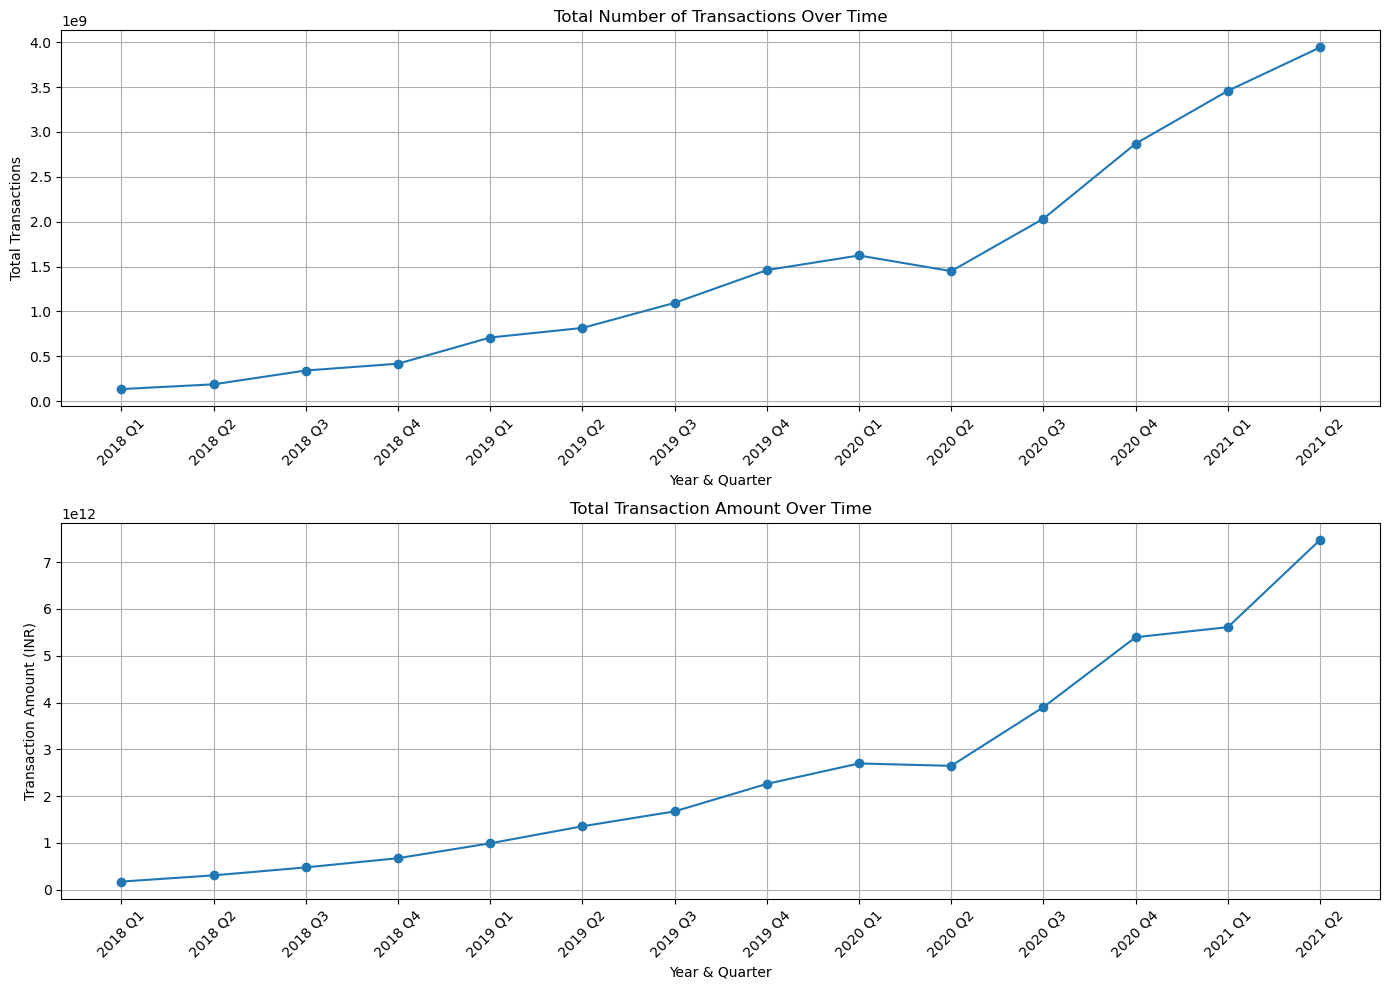

In [20]:
## Task 5 - data vislization
# 5.1 - line plot

import pandas as pd
import matplotlib.pyplot as plt

# Group by Year and Quarter
df_trend = (
    df_state_txn
    .groupby(["Year", "Quarter"])[
        ["Transactions", "Amount (INR)"]
    ]
    .sum()
    .reset_index()
)

# Create Year-Quarter column
df_trend["Year_Quarter"] = (
    df_trend["Year"].astype(str) + " Q" +
    df_trend["Quarter"].astype(str)
)

# Create two line plots
fig, ax = plt.subplots(2, 1, figsize=(14, 10))

# Plot 1: Total Transactions
ax[0].plot(
    df_trend["Year_Quarter"],
    df_trend["Transactions"],
    marker="o"
)
ax[0].set_title("Total Number of Transactions Over Time")
ax[0].set_xlabel("Year & Quarter")
ax[0].set_ylabel("Total Transactions")
ax[0].tick_params(axis="x", rotation=45)
ax[0].grid(True)

# Plot 2: Total Transaction Amount
ax[1].plot(
    df_trend["Year_Quarter"],
    df_trend["Amount (INR)"],
    marker="o"
)
ax[1].set_title("Total Transaction Amount Over Time")
ax[1].set_xlabel("Year & Quarter")
ax[1].set_ylabel("Transaction Amount (INR)")
ax[1].tick_params(axis="x", rotation=45)
ax[1].grid(True)

plt.tight_layout()
plt.show()

<Figure size 1000x1000 with 0 Axes>

([<matplotlib.patches.Wedge at 0x14a90a42f90>,
 [Text(-0.0002995494978941056, 1.0999999592136802, ''),
  Text(-0.30581811376922263, 1.0566339391154511, ''),
  Text(-0.5881792586100374, 0.9295402948452245, ''),
  Text(-0.60804732435392, 0.9166670340674629, ''),
  Text(-0.7335450218241782, 0.8197022026059013, ''),
  Text(-0.8318555821091289, 0.7197334857528045, ''),
  Text(-0.8593831275901362, 0.6866299148838447, ''),
  Text(-0.8844006254285629, 0.6540913802685119, ''),
  Text(-0.9656147090083618, 0.5268664287527695, ''),
  Text(-1.0294490664055713, 0.387601108972482, ''),
  Text(-1.0609666357631988, 0.2904303665206512, ''),
  Text(-1.095163080500931, 0.10304284112790855, ''),
  Text(-1.0999977625887807, 0.0022186256278241942, ''),
  Text(-1.099899234875041, -0.014888691053939107, ''),
  Text(-1.0977075010984723, -0.07098057503393346, ''),
  Text(-0.9487611659472732, -0.5566437370440547, ''),
  Text(-0.6024800390919479, -0.9203357009785967, ''),
  Text(-0.5671431316819049, -0.94252250274

Text(0.5, 1.0, 'State-wise Transaction Distribution - Q2 2021')

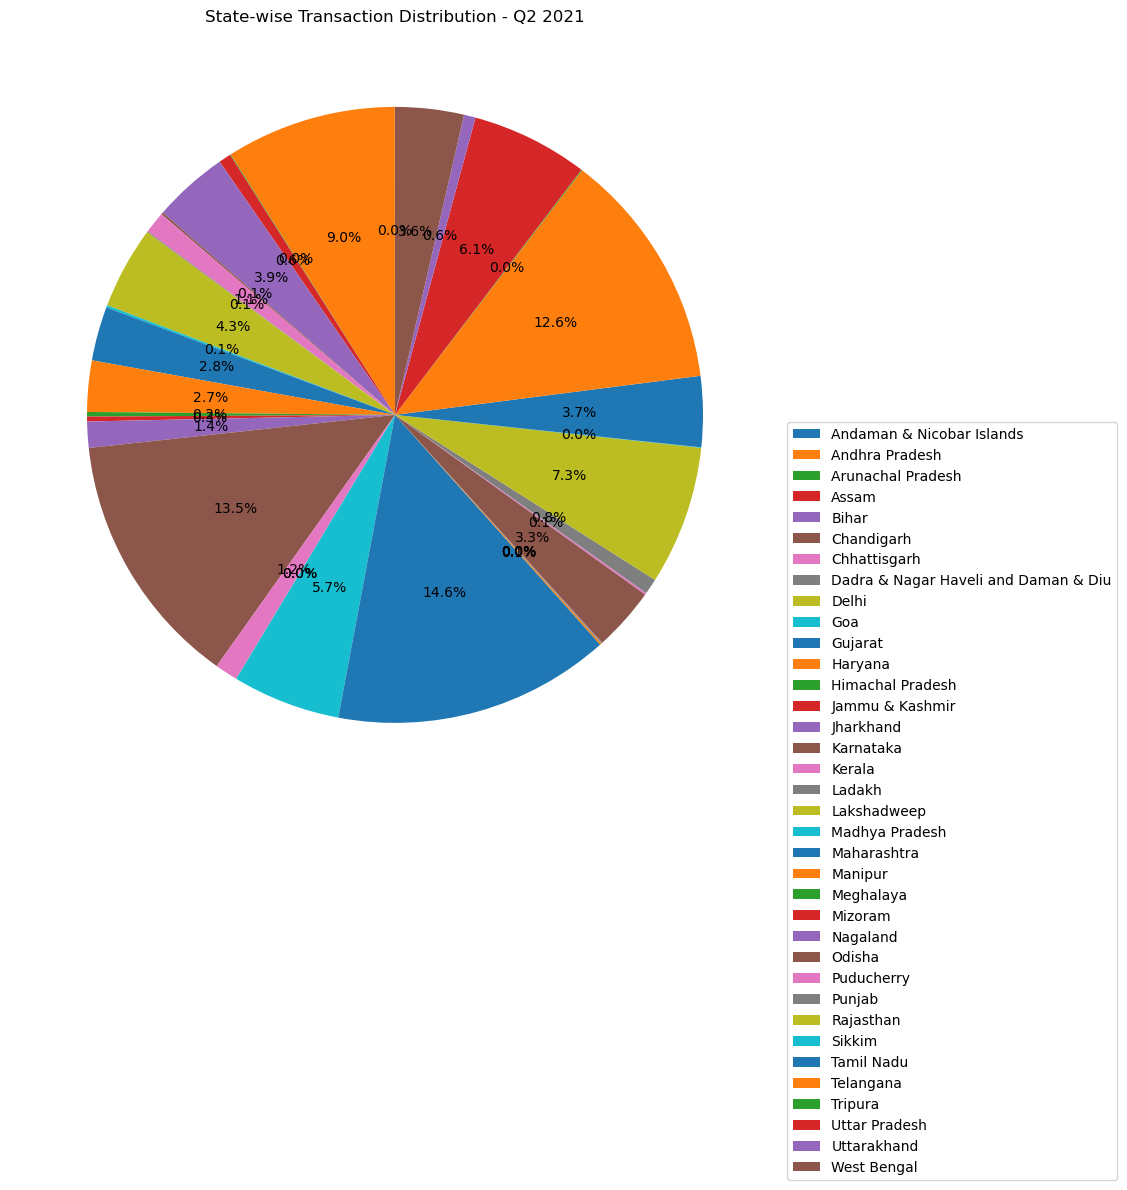

In [24]:
# 5.2 - pie chat - ditribution of transaction types for specific quarter

df_quarter = df_state_txn[
    (df_state_txn["Year"] == 2021) &
    (df_state_txn["Quarter"] == 2)
]

# Calculate transactions by state
df_pie = df_quarter.groupby("State")["Transactions"].sum()

# Create pie chart
plt.figure(figsize=(10, 10))

plt.pie(
    df_pie,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("State-wise Transaction Distribution - Q2 2021")
plt.legend(
    df_pie.index,
    loc="best",
    bbox_to_anchor=(1, 0.5)
)

plt.show()



<Figure size 1400x700 with 0 Axes>

<BarContainer object of 75 artists>

Text(0.5, 1.0, 'Population Density of Districts in Uttar Pradesh')

Text(0.5, 0, 'District')

Text(0, 0.5, 'Population Density (people per sq km)')

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40,
  41,
  42,
  43,
  44,
  45,
  46,
  47,
  48,
  49,
  50,
  51,
  52,
  53,
  54,
  55,
  56,
  57,
  58,
  59,
  60,
  61,
  62,
  63,
  64,
  65,
  66,
  67,
  68,
  69,
  70,
  71,
  72,
  73,
  74],
 [Text(0, 0, 'Ghaziabad'),
  Text(1, 0, 'Varanasi'),
  Text(2, 0, 'Hapur'),
  Text(3, 0, 'Lucknow'),
  Text(4, 0, 'Bhadohi'),
  Text(5, 0, 'Kanpur Nagar'),
  Text(6, 0, 'Meerut'),
  Text(7, 0, 'Gorakhpur'),
  Text(8, 0, 'Mau'),
  Text(9, 0, 'Moradabad'),
  Text(10, 0, 'Gautam Buddh Nagar'),
  Text(11, 0, 'Kushinagar'),
  Text(12, 0, 'Deoria'),
  Text(13, 0, 'Shamli'),
  Text(14, 0, 'Azamgarh'),
  Text(15, 0, 'Jaunpur'),
  Text(16, 0, 'Allahabad'),
  Text(17, 0, 'Agra'),
  Text(18, 0, 'Bareilly'),
  Text(19, 0, 'Ballia'),
  Text(20, 0, 'Ghazipur'),
  Tex

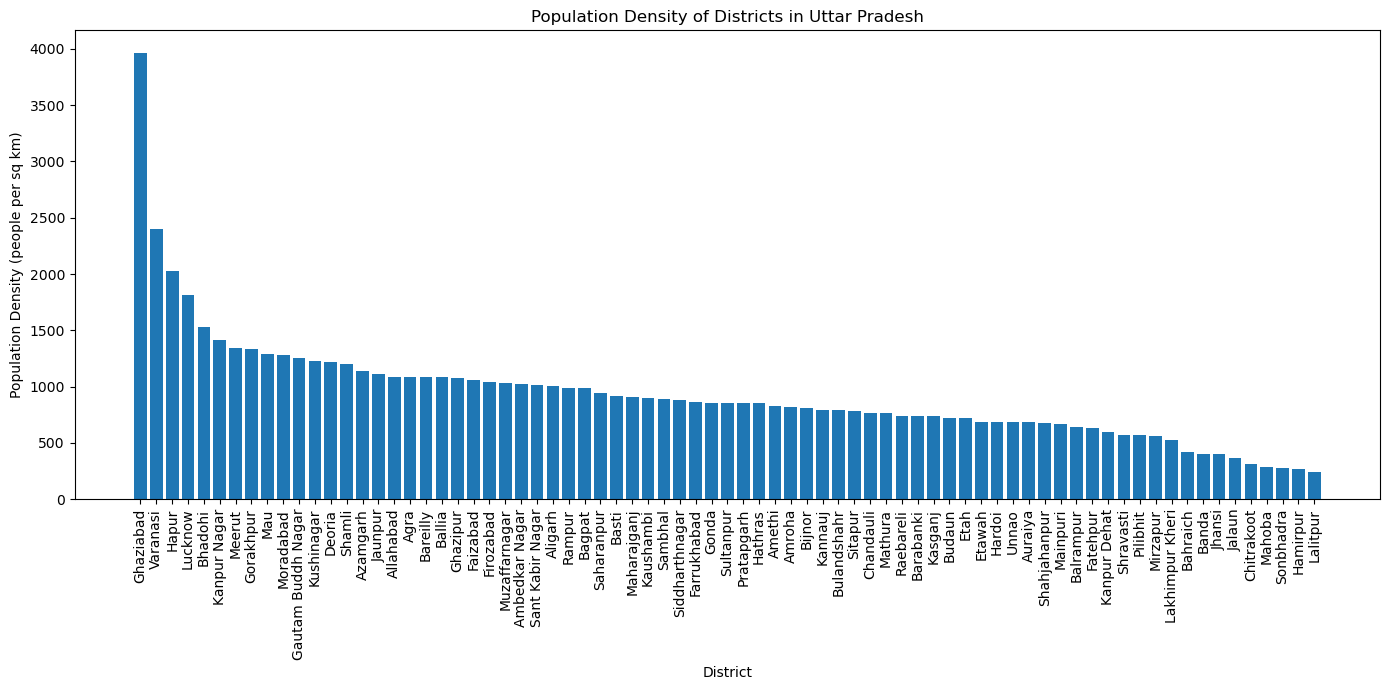

In [26]:
# 5.3 - bar plot for population denity of districts in a selected state

# Step 1: Select a state
selected_state = "Uttar Pradesh"

# Step 2: Filter districts for selected state
df_state = df_district_demo[
    df_district_demo["State"] == selected_state
]

# Step 3: Sort districts by population density
df_state = df_state.sort_values(
    by="Density",
    ascending=False
)

# Step 4: Create bar plot
plt.figure(figsize=(14, 7))

plt.bar(
    df_state["District"],
    df_state["Density"]
)

plt.title(f"Population Density of Districts in {selected_state}")
plt.xlabel("District")
plt.ylabel("Population Density (people per sq km)")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()


<Figure size 1400x600 with 0 Axes>

<Figure size 1400x600 with 0 Axes>

Text(0.5, 1.0, 'Quarterly Transaction Amount Growth (2018–2021)')

Text(0.5, 0, 'Year and Quarter')

Text(0, 0.5, 'Transaction Amount (₹ Trillion)')

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13],
 [Text(0, 0, '2018 Q1'),
  Text(1, 0, '2018 Q2'),
  Text(2, 0, '2018 Q3'),
  Text(3, 0, '2018 Q4'),
  Text(4, 0, '2019 Q1'),
  Text(5, 0, '2019 Q2'),
  Text(6, 0, '2019 Q3'),
  Text(7, 0, '2019 Q4'),
  Text(8, 0, '2020 Q1'),
  Text(9, 0, '2020 Q2'),
  Text(10, 0, '2020 Q3'),
  Text(11, 0, '2020 Q4'),
  Text(12, 0, '2021 Q1'),
  Text(13, 0, '2021 Q2')])

<Figure size 1400x600 with 0 Axes>

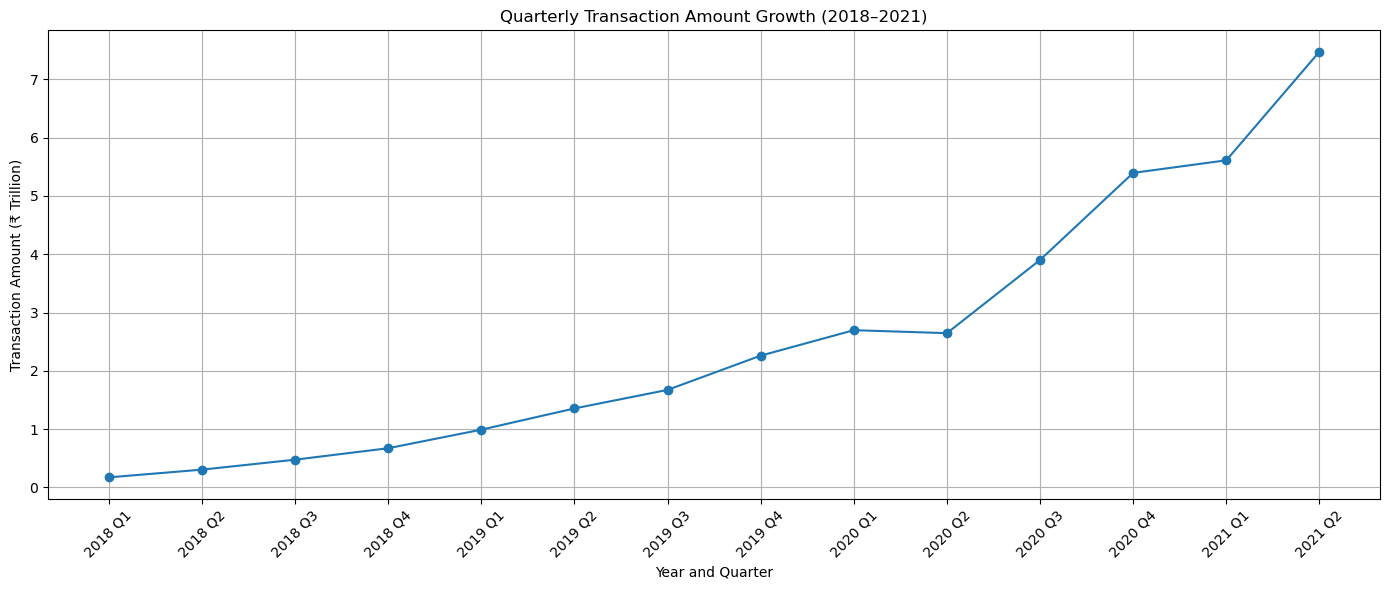

In [29]:
## Task 6 - Insights & conclusions
# 6.1 - 
# Line graph – Total transactions over time - Group data by Year and Quarter
df_trend = (
    df_state_txn
    .groupby(["Year", "Quarter"])["Transactions"]
    .sum()
    .reset_index()
)

# Create time period column
df_trend["Period"] = (
    df_trend["Year"].astype(str) +
    " Q" +
    df_trend["Quarter"].astype(str)
)

# Plot line graph
plt.figure(figsize=(14, 6))



# Group data by Year and Quarter
df_amount = (
    df_state_txn
    .groupby(["Year", "Quarter"])["Amount (INR)"]
    .sum()
    .reset_index()
)

df_amount["Period"] = (
    df_amount["Year"].astype(str) +
    " Q" +
    df_amount["Quarter"].astype(str)
)

# Line graph – Total transaction amount over time
plt.figure(figsize=(14, 6))

plt.plot(
    df_amount["Period"],
    df_amount["Amount (INR)"] / 1e12,
    marker="o"
)

plt.title("Quarterly Transaction Amount Growth (2018–2021)")
plt.xlabel("Year and Quarter")
plt.ylabel("Transaction Amount (₹ Trillion)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
## 6.1 -
### Transaction Trends and Patterns (2018–2021)

The analysis of PhonePe transaction data from Q1 2018 to Q2 2021 reveals significant growth in digital payment adoption across India.

1. **Rapid growth:** The total number of transactions increased from approximately 134 million in Q1 2018 to 3.94 billion in Q2 2021, indicating substantial growth in digital payment usage.

2. **Increasing transaction value:** Total transaction value increased from approximately ₹171.83 billion to ₹7.48 trillion during the same period.

3. **Temporary slowdown:** Q2 2020 experienced a decline in transaction volume and value compared with Q1 2020, indicating a temporary slowdown in payment activity.

4. **Strong recovery:** From Q3 2020 onwards, both transaction volume and transaction value showed strong recovery and continued growth.

5. **Overall trend:** The quarterly line graphs demonstrate a clear upward trend in PhonePe transactions and transaction value, reflecting increasing adoption of digital payment services.

**Conclusion:** PhonePe experienced substantial growth in digital payment activity between 2018 and 2021. Despite a temporary slowdown in Q2 2020, the platform recovered strongly and achieved its highest recorded transaction volume and value in Q2 2021.

In [30]:
## 6.2 correlation


# Step 1: Aggregate district demographics by State

df_state_demo = (
    df_district_demo
    .groupby("State")
    .agg({
        "Population": "sum",
        "Area (sq km)": "sum"
    })
    .reset_index()
)

# Step 2: Calculate state population density

df_state_demo["Population Density"] = (
    df_state_demo["Population"] /
    df_state_demo["Area (sq km)"]
)

# Step 3: Aggregate transaction volume by State

df_state_volume = (
    df_state_txn
    .groupby("State")["Transactions"]
    .sum()
    .reset_index()
)

# Step 4: Merge demographic and transaction data

df_corr = pd.merge(
    df_state_demo,
    df_state_volume,
    on="State",
    how="inner"
)

# Step 5: Calculate correlation

correlation = df_corr[
    ["Population Density", "Transactions"]
].corr()

print(correlation)


                    Population Density  Transactions
Population Density            1.000000     -0.034143
Transactions                 -0.034143      1.000000


In [87]:
# Identify the most common transaction types in each state Year
transactions =df_state_txn_split.groupby(['State', 'Year', 'Transaction Type'])['Transactions'].sum().reset_index()
rows = transactions.groupby(['State', 'Year'])['Transactions'].idxmax()
transactions.loc[rows]

,State,Year,Transaction Type,Transactions
4,Andaman & Nicobar Islands,2018,Recharge & bill payments,31088
9,Andaman & Nicobar Islands,2019,Recharge & bill payments,60009
14,Andaman & Nicobar Islands,2020,Recharge & bill payments,196514
18,Andaman & Nicobar Islands,2021,Peer-to-peer payments,238230
23,Andhra Pradesh,2018,Peer-to-peer payments,41504323
...,...,...,...,...
696,Uttarakhand,2021,Merchant payments,17528156
703,West Bengal,2018,Peer-to-peer payments,71705443
708,West Bengal,2019,Peer-to-peer payments,136220653
713,West Bengal,2020,Peer-to-peer payments,137306673


In [ ]:
## 6.2 - conclusion
### Correlation Between Population Density and Transaction Volume

The demographic data (`df_district_demo`) and transaction data (`df_state_txn`) were analysed to understand the relationship between population 
density and digital payment activity across Indian states.

District-level demographic information was first aggregated to the state level. State population density was calculated using total population divided
by total geographical area. Transaction volumes were also aggregated by state, and both datasets were merged for correlation analysis.

**Key Findings:**

1. The Pearson correlation coefficient between population density and total transaction volume is approximately **-0.034**, indicating a very weak 
negative linear relationship.

2. Higher population density does not necessarily result in higher digital transaction volumes.

3. Transaction activity may depend on several other factors, including population size, digital infrastructure, smartphone penetration and economic 
development.

4. Delhi is an important outlier because of its exceptionally high population density. However, excluding Delhi does not materially change the overall
conclusion.

**Conclusion:**

The analysis indicates that population density alone is not a strong predictor of PhonePe transaction volume across states. Other demographic, 
economic and technological factors are likely to play an important role in determining digital payment adoption and usage.

In [ ]:
## 6.3 - summarize findings & insights
PhonePe demonstrated strong growth in India's digital payment market between 2018 and 2021. The findings suggest that future growth should focus not 
only on increasing the existing customer base but also on expanding merchant acceptance, improving digital payment accessibility and identifying 
underserved markets. Population density should be considered alongside population size, digital infrastructure and actual transaction adoption when 
selecting new growth opportunities.